# Prova 1
Data: 15.10.2026

- Michelini Tommaso
- Marsilio Mariafrancesca
- Manzini Martina
- Mauro Rossi


In [1]:
import numpy as np 
import matplotlib.pyplot as plt
from scipy import stats


ROSSO = "#C92512"
GRIGIO = "#5A5A5A"
AZZURRO = "#2E6F9E"
ORO = "#D79B00"
plt.rcParams.update({
    "figure.figsize": (8.2, 4.6),
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.labelsize": 11,
    "axes.titlesize": 12,
    "font.size": 11,
    "legend.frameon": False,
})

# Attività 1

finita: True
non negativa: True
simmetrica: True


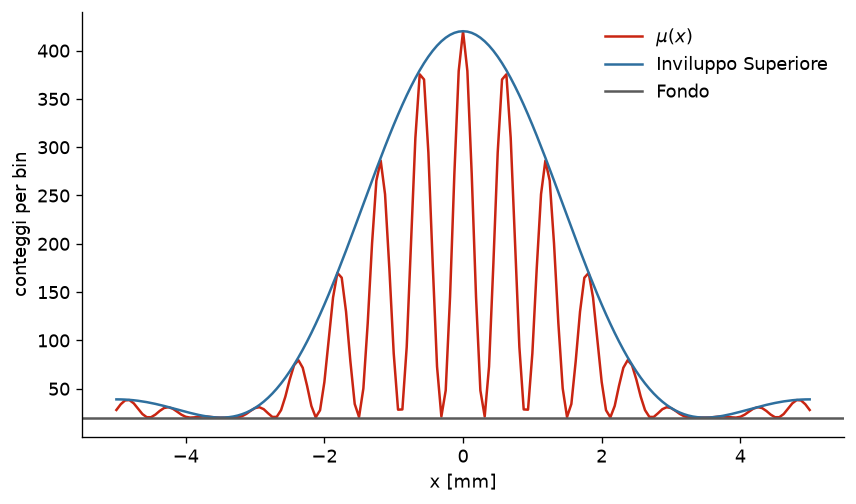

(<matplotlib.legend.Legend at 0x7765f0943fe0>, None)

In [2]:
B = 20
I0 = 400
alpha = 0.90
delta = 5.20
x_min = -5.0
x_max = 5.0

x = np.linspace(x_min, x_max, 161)


E = np.sinc(alpha*x/np.pi)**2
C = np.cos(delta*x)**2
mu =  B + (I0 * E) * C

print(f"finita: {np.isfinite(mu).all()}")
print(f"non negativa: {(mu >= 0).all()}")
print(f"simmetrica: {np.allclose(mu, mu[::-1])}")
#dimostrare compatibilità con B + I0

plt.plot(x, mu, color=ROSSO, label=r"$\mu(x)$")
plt.xlabel("x [mm]")
plt.ylabel("conteggi per bin")
plt.plot(x, B + I0 * E, color=AZZURRO, label="Inviluppo Superiore")
plt.axhline(B, color=GRIGIO, label= "Fondo")

plt.legend(), plt.show()




# Attività 2

N_c è di Poisson con media μ_c e deviazione standard √μ_c. La differenza osservata è Z = |N_c − μ_c| / √μ_c ≈ 1.3, con p-value a due code p ≈ 0.19. Se il modello è corretto, una differenza così grande si osserva per sola fluttuazione statistica circa nel 19% dei casi, quindi N_c è compatibile con μ_c. 

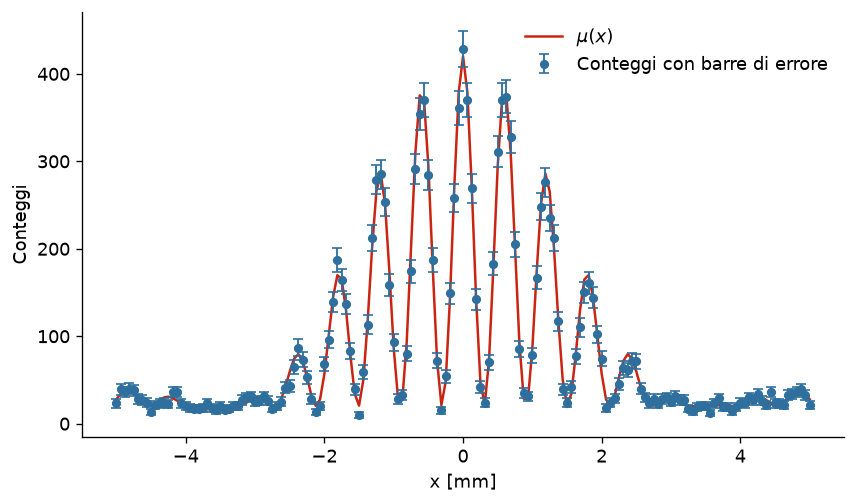

N_c - mu_c = -113.41304189733182
sigma = 87.46092294217648
Z = 1.297 sigma
p-value = 0.195


In [3]:
rng = np.random.default_rng(12345)

n_i = rng.poisson(mu)
x_sup = np.abs(x) < 1.2
n_error = np.sqrt(n_i)
n_error[n_i == 0] = 1.0

plt.plot(x, mu, color=ROSSO, label=r"$\mu(x)$")
plt.errorbar(
    x,
    n_i,
    yerr=n_error,
    fmt="o",
    linestyle="none",
    color=AZZURRO,
    markersize=4.5,
    capsize=3,
    elinewidth=1.1,
    label="Conteggi con barre di errore"
)
plt.xlabel("x [mm]")
plt.ylabel("Conteggi")

plt.legend(), plt.show()


N_c = np.sum(n_i[x_sup])
mu_c = np.sum(mu[x_sup])


print(f"N_c - mu_c = {N_c - mu_c}")
print(f"sigma = {np.sqrt(mu_c)}")

Z = np.abs(N_c - mu_c) / np.sqrt(mu_c)
p_value = 2*(1-stats.norm.cdf(abs(Z)))

print(f"Z = {Z:.3f} sigma")
print(f"p-value = {p_value:.3f}")


# Attività 3

Media: 7650.7665
Deviazione Standard: 87.75160482763214
Sigma teorica attesa: 87.46092294217648
Deviazione Standard della Media: 1.9621855352928417
Scarto relativo: 0.00017693620350407878


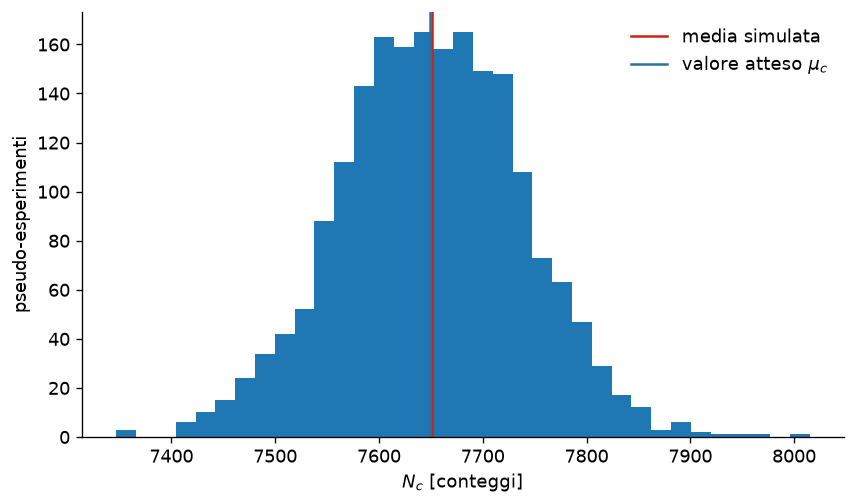

(<matplotlib.legend.Legend at 0x7765f09eef00>, None)

In [4]:
M = 2000

n_sim = rng.poisson(mu, (M, len(x)))
N_c_sim = []

for i in range(M):
    somma = np.sum(n_sim[i, x_sup])
    N_c_sim.append(somma)

print(f"Media: {np.mean(N_c_sim)}")
print(f"Deviazione Standard: {np.std(N_c_sim, ddof=1)}")
print(f"Sigma teorica attesa: {np.sqrt(mu_c)}")
print(f"Deviazione Standard della Media: {np.std(N_c_sim, ddof=1) / np.sqrt(M)}")
print(f"Scarto relativo: {(np.mean(N_c_sim) - mu_c) / mu_c}")

plt.hist(N_c_sim, bins=35)
plt.axvline(np.mean(N_c_sim), color=ROSSO, label="media simulata")
plt.axvline(mu_c, color=AZZURRO, label=r"valore atteso $\mu_c$")
plt.xlabel(r"$N_c$ [conteggi]")
plt.ylabel("pseudo-esperimenti")
plt.legend(), plt.show()


In [5]:
np.savetxt('dati_fit_interferenza.csv', 
           np.column_stack((x, n_i, n_error))
           , delimiter =',', header="x,y,sigma_y", comments='')